<a href="https://colab.research.google.com/github/garrettdsparks/SDP-CSE21-ME24/blob/elliston-dev/boiler_part_identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install Ultralytics and Pytorch, verify GPU access.

In [36]:
!pip install -q ultralytics

# Verify that the T4 GPU is assigned and active
import torch
print(f"PyTorch Version: {torch.__version__}") # Not used yet, but ideally would be for audio detection
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

PyTorch Version: 2.11.0+cu130
CUDA Available: True
Device Name: Tesla T4


Mount Google Drive for data storage. This will save the hyperparameters and training results once ephemeral Colab runtime disconnects.

In [37]:
from google.colab import drive
drive.mount('/content/drive')

import os
# Create a dedicated directory in Drive
save_dir = "/content/drive/MyDrive/SDP_Practice"
os.makedirs(save_dir, exist_ok=True)
print(f"Output directory ready: {save_dir}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output directory ready: /content/drive/MyDrive/SDP_Practice


Access Roboflow, then train on GPU and direct checkpoints to Drive.

In [38]:
!pip install -q roboflow

from google.colab import userdata
from roboflow import Roboflow

# Initialize Roboflow using the retrieved key
rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY')) # Stored in Colab Secrets
project = rf.workspace("ellistons-workspace").project("sdp-team-21")
version = project.version(9)
dataset = version.download("yolov8")

print(f"Dataset v{version.version} successfully downloaded to: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 61.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to SDP-Team-21-9 in yolov8:: 100%|██████████| 149/149 [00:00<00:00, 7400.60it/s]

Dataset v9 successfully downloaded to: /content/SDP-Team-21-9


Train model on a small annotated boiler dataset. This dataset includes 18 images, with 14 in the training set and 4 in the validation set. Annotations include boiler bodies, gas trains, burners, and pressure gauges.

In [39]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=40,
    imgsz=640,
    batch=8,
    device=0,
    project=save_dir,
    name="boiler_tuned_hparams",
    exist_ok=True,

    optimizer="auto",
    lr0=0.01,
    box=7.5,
    cls=0.5,
    mosaic=1.0,
    scale=0.5
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SDP-Team-21-9/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=boiler_tuned_hparams, nbs=64, nms=None, opset=None, optimi

Test inference and display the output inline


image 1/1 /content/SDP-Team-21-9/valid/images/endustriyel-buhar-kazani-secerken-nelere-dikkat-edilmeli_2_webp.rf.a7a359bde1950e6772025ebb0e92e9a9.jpg: 640x640 1 Boiler, 1 burner_assembly, 2 pressure_gauges, 12.2ms
Speed: 0.8ms preprocess, 12.2ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/SDP_Practice/boiler_inference_output

--- Detections for endustriyel-buhar-kazani-secerken-nelere-dikkat-edilmeli_2_webp.rf.a7a359bde1950e6772025ebb0e92e9a9.jpg ---
Total objects identified: 4
  • pressure_gauge (confidence: 71.79%)
  • Boiler (confidence: 64.09%)
  • pressure_gauge (confidence: 58.38%)
  • burner_assembly (confidence: 57.03%)


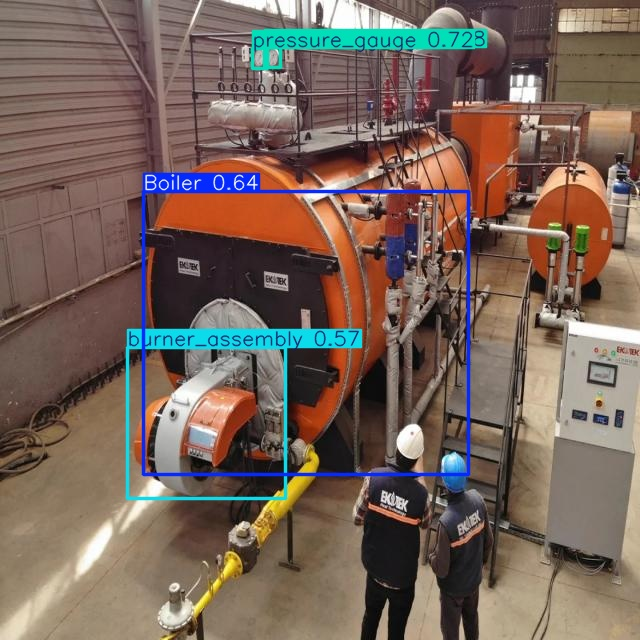

In [43]:
import glob
import os
from PIL import Image

# Point directly to the weights from the transfer run
best_weights = os.path.join(save_dir, "boiler_tuned_hparams", "weights", "best.pt")
trained_model = YOLO(best_weights)

# Retrieve a valid image from valid split
candidate_images = (glob.glob(f"{dataset.location}/valid/images/*.*"))

sample_image = candidate_images[1]
image_name = os.path.basename(sample_image)

# Run inference
pred_results = trained_model.predict(
    source=sample_image,
    conf=0.50,
    iou=0.50,
    save=True,
    project=save_dir,
    name="boiler_inference_output",
    exist_ok=True
)

# Print detected classes and confidence values
boxes = pred_results[0].boxes
print(f"\n--- Detections for {image_name} ---")
print(f"Total objects identified: {len(boxes)}")
for box in boxes:
    cls_id = int(box.cls[0].item())
    label = trained_model.names[cls_id]
    conf_score = float(box.conf[0].item())
    print(f"  • {label} (confidence: {conf_score:.2%})")

# Render output image inline
output_path = os.path.join(pred_results[0].save_dir, image_name)
display(Image.open(output_path))